In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

In [ ]:
# 1. Load Data
df = pd.read_csv("titanic.csv")
print("Dataset Loaded Successfully\n")

Dataset Loaded Successfully



In [ ]:
print("First 5 rows")
print(df.head())

First 5 rows
   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]


In [ ]:
#Shape of Dataset(rows, columns)
print("\nShape of Dataset:", df.shape)


Shape of Dataset: (891, 12)


In [ ]:
#Data type and non-null counts
print("\nInfo about Dataset: ")
print(df.info())


Info about Dataset: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [ ]:
# 2. Handling Missing Data
print("\nMissing Value in each column:")
print(df.isnull().sum())


Missing Value in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)
df.drop('Cabin', axis=1, inplace=True)

/tmp/ipykernel_934/3906006821.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)
/tmp/ipykernel_934/3906006821.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.12/dist-packages/matplotlib/pyplot.py'>

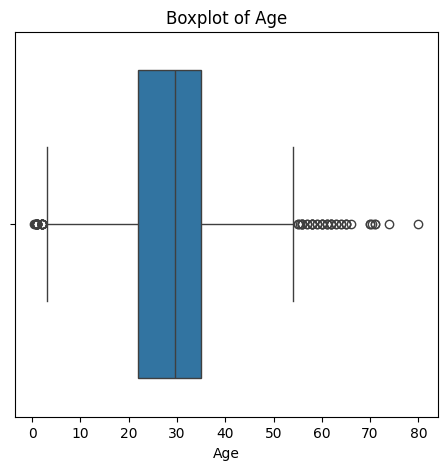

In [ ]:
# 3.Detecting and Handling Outliers

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['Age'])
plt.title('Boxplot of Age')
plt

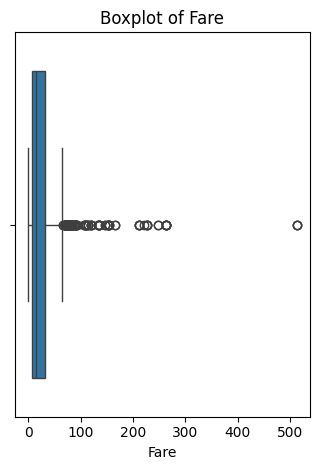

In [ ]:
plt.subplot(1,2,2)
sns.boxplot(x=df['Fare'])
plt.title('Boxplot of Fare')
plt.tight_layout()
plt.show()

In [ ]:
#Handling Outliers using IQR method(for "Fare")
q1 = df['Fare'].quantile(0.25)
q3 = df['Fare'].quantile(0.75)
IQR = q3 - q1

In [ ]:
#define outier boundaries
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

In [ ]:
df['Fare'] = np.where(df['Fare']> upper_bound , upper_bound,
                      np.where(df['Fare']< lower_bound , lower_bound, df['Fare']))

In [ ]:
# 4. Feature Scaling

#Using StandardScaler on Age anf Fare
scaler = StandardScaler()

#Reshaping required for fitting scaler
df[['Age' , 'Fare']] = scaler.fit_transform(df[['Age' , 'Fare']])

#Displaying Scaled data
print("\nScaled Age and Fare( first 5 rows): ")
print(df[['Age' , 'Fare']].head())


Scaled Age and Fare( first 5 rows): 
        Age      Fare
0 -0.592481 -0.820552
1  0.638789  2.031623
2 -0.284663 -0.787578
3  0.407926  1.419297
4  0.407926 -0.781471


In [ ]:
# 5. Encoding Categorical Variables
print("\nCategorical Columns:")
print(df.select_dtypes(include='object').columns.tolist())

df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

print("\nData after Encoding:")
print(df.head())


Categorical Columns:
['Name', 'Sex', 'Ticket', 'Embarked']

Data after Encoding:
   PassengerId  Survived  Pclass  ... Sex_male  Embarked_Q  Embarked_S
0            1         0       3  ...     True       False        True
1            2         1       1  ...    False       False       False
2            3         1       3  ...    False       False        True
3            4         1       1  ...    False       False        True
4            5         0       3  ...     True       False        True

[5 rows x 12 columns]
